In [41]:
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt
import requests
import pandas as pd

In [42]:
# read in curb spaces from the Seattle ArcGIS API (paged, server returns max 2000 rows per request)
import pandas as pd

URL = ("https://services.arcgis.com/ZOyb2t4B0UYuYNYH/arcgis/rest/services/"
       "Curb_Space_Categories/FeatureServer/6/query")

# rows per request; the server won't return more than its max at once
PAGE_SIZE = 2000

pages = []
offset = 0
while True:
    r = requests.get(URL, params={
        "where": "1=1",
        "outFields": "*", # return all columns
        "f": "geojson",  # response format: GeoJSON
        "orderByFields": "OBJECTID",
        "resultOffset": offset, # skip this many rows (start of this page)
        "resultRecordCount": PAGE_SIZE, # how many rows to return in this page
    }, timeout=60)
    r.raise_for_status()
    data = r.json()
    if "error" in data:
        raise RuntimeError(data["error"])
    if not data["features"]:
        break
    pages.append(gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326"))
    offset += PAGE_SIZE

curb_spaces = pd.concat(pages, ignore_index=True)
print(curb_spaces.shape)

# Coordinate Reference System
print(curb_spaces.crs) 
# CRS defines how the numbers in geometry map to real locations on earth

print(curb_spaces.columns.tolist())

curb_spaces.head()

(40516, 28)
EPSG:4326
['geometry', 'OBJECTID', 'BLOCKID', 'BLOCK_ST', 'BLOCK_END', 'WIDTH_OFFSET', 'GEOBASYS', 'SPACELENGTH', 'SPACETYPE', 'SPACETYPEDESC', 'TIME_LIMIT', 'SPACE_NB', 'CATEGORY', 'SIDE', 'CURRENT_STATUS', 'ELMNTKEY', 'SPACEKEY', 'SEGKEY', 'PRIMARYDISTRICTCD', 'SECONDARYDISTRICTCD', 'OVERRIDEYN', 'OVERRIDECOMMENT', 'PAIDAREA', 'SUBAREA', 'UNIQUEID', 'STOPSTATUS', 'STOP_STATUS_DESCRIPTION', 'Shape__Length']


,geometry,OBJECTID,BLOCKID,BLOCK_ST,BLOCK_END,WIDTH_OFFSET,GEOBASYS,SPACELENGTH,SPACETYPE,SPACETYPEDESC,...,PRIMARYDISTRICTCD,SECONDARYDISTRICTCD,OVERRIDEYN,OVERRIDECOMMENT,PAIDAREA,SUBAREA,UNIQUEID,STOPSTATUS,STOP_STATUS_DESCRIPTION,Shape__Length
0,"LINESTRING (-122.3416 47.61057, -122.34166 47....",405358,01-19,120.0,137.0,-26,None,17,PS,PAY STATION,...,DISTRICT7,,N,None,Belltown,South,None,,None,16.998414
1,"LINESTRING (-122.31431 47.61331, -122.31431 47...",405359,E14-14,144.0,150.0,30,None,6,CLR,CLEARANCE,...,DISTRICT3,,N,None,Pike-Pine,None,None,,None,5.996752
2,"LINESTRING (-122.3334 47.60479, -122.33343 47....",405360,03-08,273.0,288.0,31,None,15,XWAREA,NOT A DESIGNATED CROSSWALK,...,DISTRICT7,,N,None,Commercial Core,Financial,None,,None,14.996317
3,"LINESTRING (-122.31277 47.62088, -122.31277 47...",405361,EE15-03,138.0,156.0,20,None,18,PS,PAY STATION,...,DISTRICT3,,N,None,15th Avenue E,None,None,,None,17.960026
4,"LINESTRING (-122.32741 47.6779, -122.32742 47....",405362,NE2-66,129.0,134.0,16,None,5,CLR,CLEARANCE,...,DISTRICT6,,N,None,Green Lake,None,None,,None,4.993544


In [43]:
print(curb_spaces[['SPACETYPE', 'SPACETYPEDESC']].drop_duplicates().sort_values('SPACETYPE').reset_index(drop=True).to_string())


   SPACETYPE                       SPACETYPEDESC
0      ALLEY                               ALLEY
1         BA                        BARRIER AREA
2       BIKE                           BIKE ZONE
3        BUS                            BUS ZONE
4     BUSLAY                    BUS LAYOVER ZONE
5      CHRTR                    CHARTER BUS ZONE
6        CLR                           CLEARANCE
7         CR                           CURB RAMP
8     CRBBLB                           CURB BULB
9       CRPL         CARPOOL PARKING - FULL TIME
10        CS                    CARSHARE/FLEXCAR
11      CVLZ        COMMERCIAL VEHICLE LOAD ZONE
12    CVLZ-B                     CVLZ - BUS ZONE
13    CVLZ-P                          CVLZ - PLZ
14        CZ                      CONSULATE ZONE
15    DISABL                       DISABLED ZONE
16        DW                            DRIVEWAY
17       HYD                             HYDRANT
18      L/UL                    LOAD/UNLOAD ZONE
19    L/UL-P        

In [44]:
# check space type 
print(curb_spaces['SPACETYPEDESC'].value_counts().to_string())


SPACETYPEDESC
CLEARANCE                             9856
PAY STATION                           9302
CROSSWALK                             3664
NO PARKING                            3617
DRIVEWAY                              2070
CURB RAMP                             1438
PAY STATION - RES PARKING ZONE        1385
NOT A DESIGNATED CROSSWALK            1123
CURB BULB                             1098
LOAD/UNLOAD ZONE                       848
TOW AWAY ZONE                          794
PASSENGER LOAD ZONE                    719
ALLEY                                  472
COMMERCIAL VEHICLE LOAD ZONE           413
UNRESTRICTED                           395
PAY STATION - TEMP REMOVAL             371
TIME LIMIT - RES PARKING ZONE          359
HYDRANT                                317
BARRIER AREA                           311
BUS ZONE                               289
TIME LIMIT                             257
DISABLED ZONE                          200
PAY STATION - BUS LAYOVER              1

General load/unload (4) – 935

LOAD/UNLOAD ZONE – 848
PAY STATION - LOAD/UNLOAD ZONE – 61
TIME LIMIT - LOAD/UNLOAD ZONE – 21
FULL-TIME PAID LOADING – 5

Commercial/truck (4) – 464

COMMERCIAL VEHICLE LOAD ZONE – 413
TRUCK LOAD/UNLOAD ZONE – 26
PAY STATION - CVLZ – 24
TIME LIMIT - TRUCK L/U ZONE – 1

Passenger, PLZ (4) – 831

PASSENGER LOAD ZONE – 719
PAY STATION - PLZ – 91
PASSENGER LOAD ZONE - VENDING ZONE – 12
TIME LIMIT - PLZ – 9

Shared/hybrid (2) – 46

CVLZ - PLZ – 44
CVLZ - BUS ZONE – 2

*NEED TO FIGURE OUT WHAT THE LAWS ARE LIKE FOR EACH TYPE*

In [45]:
# group loading zone types (from the markdown cell above) by SPACETYPEDESC
LOADING_GROUPS = {
    "General load/unload": ["LOAD/UNLOAD ZONE", "PAY STATION - LOAD/UNLOAD ZONE",
                            "TIME LIMIT - LOAD/UNLOAD ZONE", "FULL-TIME PAID LOADING"],
    "Commercial/truck": ["COMMERCIAL VEHICLE LOAD ZONE", "TRUCK LOAD/UNLOAD ZONE",
                         "PAY STATION - CVLZ", "TIME LIMIT - TRUCK L/U ZONE"],
    "Passenger (PLZ)": ["PASSENGER LOAD ZONE", "PAY STATION - PLZ",
                        "PASSENGER LOAD ZONE - VENDING ZONE", "TIME LIMIT - PLZ"],
    "Shared/hybrid": ["CVLZ - PLZ", "CVLZ - BUS ZONE"],
}

# reverse lookup: description -> group name
desc_to_group = {d: g for g, descs in LOADING_GROUPS.items() for d in descs}

loading = curb_spaces[curb_spaces["SPACETYPEDESC"].isin(desc_to_group)].copy()
loading["zone_group"] = loading["SPACETYPEDESC"].map(desc_to_group)

print(loading.shape)
print(loading["zone_group"].value_counts())

(2276, 29)
zone_group
General load/unload    935
Passenger (PLZ)        831
Commercial/truck       464
Shared/hybrid           46
Name: count, dtype: int64


In [46]:
curb_spaces['PAIDAREA'].value_counts()

PAIDAREA
Belltown               5353
South Lake Union       5205
Commercial Core        4192
First Hill             3644
Uptown                 3220
University District    2646
Denny Triangle         2354
Pioneer Square         2289
Pike-Pine              2103
Chinatown/ID           1689
Ballard                1527
Capitol Hill           1202
Westlake Ave N          856
Uptown Triangle         668
Green Lake              515
Columbia City           372
15th Avenue E           331
Roosevelt               299
12th Avenue             221
Fremont                 178
Ballard Blocks          150
Cherry Hill             141
Ballard Locks           106
Lake Union Park          44
Name: count, dtype: int64

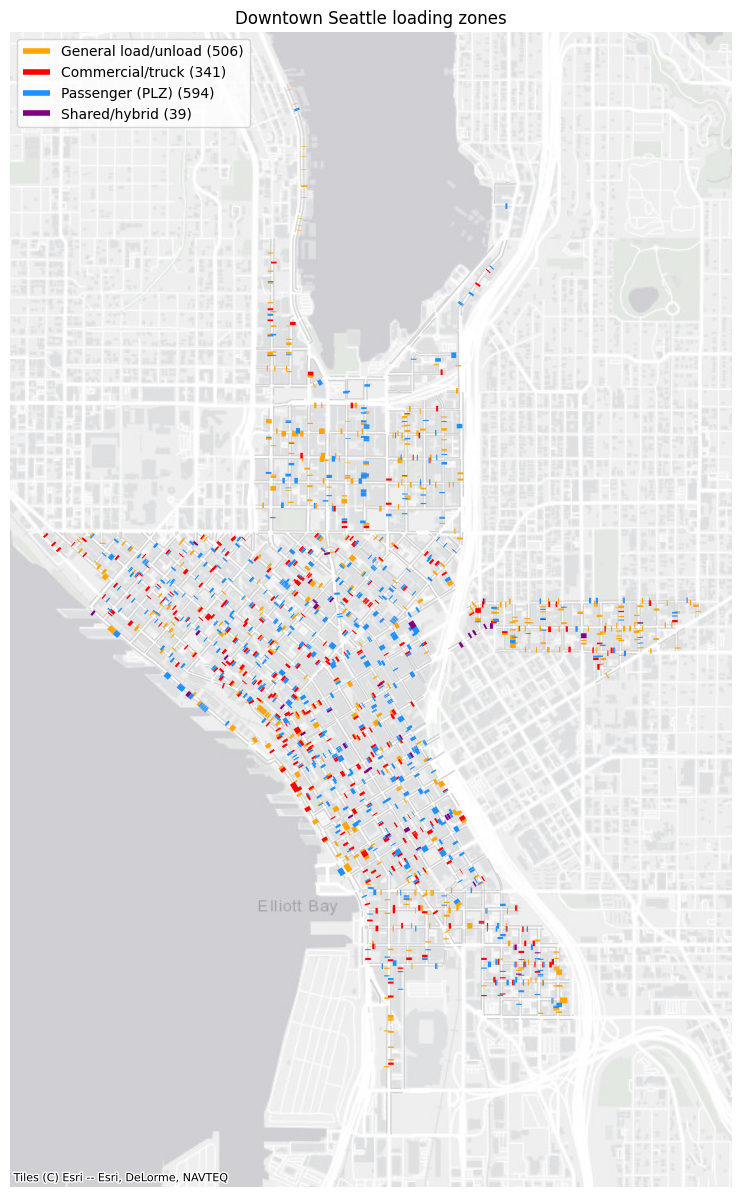

In [47]:
# map loading zones; edit DOWNTOWN_AREAS (PAIDAREA values) to define the study area
DOWNTOWN_AREAS = ["Belltown", "Commercial Core", "Denny Triangle", "Pioneer Square",
                  "South Lake Union", "Pike-Pine", "Chinatown/ID", "Westlake Ave N"]

COLORS = {"General load/unload": "orange", "Commercial/truck": "red",
          "Passenger (PLZ)": "dodgerblue", "Shared/hybrid": "purple"}

# basemap tiles are in Web Mercator (EPSG:3857), so reproject before plotting
dt_all = curb_spaces[curb_spaces["PAIDAREA"].isin(DOWNTOWN_AREAS)].to_crs(epsg=3857)
dt_load = loading[loading["PAIDAREA"].isin(DOWNTOWN_AREAS)].to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(15, 15))
dt_all.plot(ax=ax, color="lightgray", linewidth=1)  # all curb space as context
for group, color in COLORS.items():
    sub = dt_load[dt_load["zone_group"] == group]
    sub.plot(ax=ax, color=color, linewidth=4, label=f"{group} ({len(sub)})")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper left")
ax.set_axis_off()
ax.set_title("Downtown Seattle loading zones")
plt.show()

# SMART PROJECT DATA

In [48]:
# read in 3 rounds of data
idax_1 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 1 Data Collection.csv')
idax_2 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 2 Data Collection.csv')
idax_3 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 3 Data Collection.csv')

print(idax_1.head())
print(idax_2.head())
print(idax_3.head())

   Event_NB  IDAX_Site_NB  ufl_block_id ufl_blockface_id  \
0         1             1            87             87SW   
1         2             1            87             87SW   
2         3             1            87             87SW   
3         4             1            87             87SW   
4         5             1            87             87SW   

                                 unitdesc BLOCK_ID  ELMNTKEY SPACETYPE  \
0  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
1  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
2  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713       PLZ   
3  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
4  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   

  SPACE_NB Concatenated_SPACE_NB  ... activity_type commercial_logo  \
0      -12              02-23-12  ...       Private          <null>   
1      -04              02-23-04  ...       Private 

In [49]:
dfs = {"idax_1": idax_1, "idax_2": idax_2, "idax_3": idax_3}
cols = {name: set(df.columns) for name, df in dfs.items()}

all_cols = sorted(set.union(*cols.values()))
presence = pd.DataFrame({name: [c in cols[name] for c in all_cols] for name in dfs}, index=all_cols)
presence

,idax_1,idax_2,idax_3
BLOCK_ID,True,True,True
CVLZ_permit_vid,True,False,False
Concatenated_PRIMARY_SPACE_NB,False,True,False
Concatenated_SECONDARY_SPACE_NB,False,True,False
Concatenated_SPACE_NB,True,False,False
Curbside_Location,False,True,False
Date,True,True,True
Dwell,False,True,False
ELMNTKEY,True,True,True
Event_NB,True,True,False


In [50]:
# use DOWNTOWN_AREAS from curb_spaces to get BLOCK ID and see which exists in IDAF 
dt_blockid = curb_spaces['BLOCKID'][curb_spaces['PAIDAREA'].isin(DOWNTOWN_AREAS)].unique()

In [51]:
# lookup: one row per SPACETYPE code
spacetype_lookup = (curb_spaces[['SPACETYPE', 'SPACETYPEDESC']]
                    .drop_duplicates()
                    .sort_values('SPACETYPE')
                    .reset_index(drop=True))

assert spacetype_lookup['SPACETYPE'].is_unique, \
    spacetype_lookup[spacetype_lookup['SPACETYPE'].duplicated(keep=False)]


In [52]:
print(curb_spaces[['SPACETYPE', 'SPACETYPEDESC']].drop_duplicates().sort_values('SPACETYPE').reset_index(drop=True).to_string())


   SPACETYPE                       SPACETYPEDESC
0      ALLEY                               ALLEY
1         BA                        BARRIER AREA
2       BIKE                           BIKE ZONE
3        BUS                            BUS ZONE
4     BUSLAY                    BUS LAYOVER ZONE
5      CHRTR                    CHARTER BUS ZONE
6        CLR                           CLEARANCE
7         CR                           CURB RAMP
8     CRBBLB                           CURB BULB
9       CRPL         CARPOOL PARKING - FULL TIME
10        CS                    CARSHARE/FLEXCAR
11      CVLZ        COMMERCIAL VEHICLE LOAD ZONE
12    CVLZ-B                     CVLZ - BUS ZONE
13    CVLZ-P                          CVLZ - PLZ
14        CZ                      CONSULATE ZONE
15    DISABL                       DISABLED ZONE
16        DW                            DRIVEWAY
17       HYD                             HYDRANT
18      L/UL                    LOAD/UNLOAD ZONE
19    L/UL-P        

In [53]:
# left join onto each IDAX round
idax_1 = idax_1.merge(spacetype_lookup, on='SPACETYPE', how='left', validate='m:1')
idax_2 = idax_2.merge(spacetype_lookup, on='SPACETYPE', how='left', validate='m:1')
idax_3 = idax_3.merge(spacetype_lookup, on='SPACETYPE', how='left', validate='m:1')

In [54]:
# check: how many IDAX rows didn't find a match
for name, df in {"idax_1": idax_1, "idax_2": idax_2, "idax_3": idax_3}.items():
    print(name, df.shape, "unmatched:", df['SPACETYPEDESC'].isna().sum())

idax_1 (8182, 31) unmatched: 912
idax_2 (384, 23) unmatched: 0
idax_3 (263, 16) unmatched: 0


In [55]:
# find the unmatched in idax_1 
idax_1[idax_1['SPACETYPEDESC'].isna()]['SPACETYPE'].unique()

array(['TRAVEL LANE', 'SIDEWALK', 'CRB', 'NP/CRB', 'DP', 'CVLZ/PS',
       'CURB', 'LOAD', 'PLZ/TAZ'], dtype=object)

In [56]:
# check space type 
idax_1['SPACETYPEDESC'].value_counts(dropna=False)

SPACETYPEDESC
PAY STATION                     2576
COMMERCIAL VEHICLE LOAD ZONE    1639
PASSENGER LOAD ZONE              988
NaN                              912
SHUTTLE BUS ONLY                 498
BUS ZONE                         381
NO PARKING                       290
PAY STATION - CVLZ               189
TOW AWAY ZONE                    175
DRIVEWAY                         171
HYDRANT                          162
LOAD/UNLOAD ZONE                 122
CROSSWALK                         42
ALLEY                             18
PAY STATION - VENDOR              10
CURB RAMP                          9
Name: count, dtype: int64

In [57]:
# select only COMMERCIAL VEHICLE LOAD ZONE, PAY STATION - CVLZ, LOAD/UNLOAD ZONE 
idax1_loading_zones = idax_1.copy()
idax1_loading_zones = idax1_loading_zones[idax1_loading_zones['SPACETYPEDESC'].
                                          isin(['COMMERCIAL VEHICLE LOAD ZONE', 
                                                'PAY STATION - CVLZ', 
                                                'LOAD/UNLOAD ZONE'])]

In [58]:
# check body_type 
counts = idax1_loading_zones['body_type'].value_counts(dropna=False)
pd.DataFrame({
    "count": counts,
    "percent": (counts / counts.sum() * 100).round(1),
})


,count,percent
body_type,,
Passenger Vehicle,1576,80.8
Van,143,7.3
Single Unit Truck,90,4.6
Step-Van,53,2.7
Minivan,41,2.1
CM Pickup,24,1.2
Bus/Other Transit,17,0.9
Motorcycle,3,0.2
Trailer Truck,2,0.1


In [59]:
# also look at activity type
counts = idax1_loading_zones['activity_type'].value_counts(dropna=False)
pd.DataFrame({
    "count": counts,
    "percent": (counts / counts.sum() * 100).round(1),
})


,count,percent
activity_type,,
Private,1157,59.3
Rideshare,186,9.5
Food Delivery,178,9.1
Parcel Carrier,159,8.2
Goods Transport,84,4.3
Service,73,3.7
General Commercial (CM),68,3.5
Truck Rental,19,1.0
Other Transit,16,0.8


In [60]:
# cross tab
(pd.crosstab(idax1_loading_zones['body_type'],
             idax1_loading_zones['activity_type'],
             normalize='index',
             dropna=False) * 100).round(1)


activity_type,Construction,Emergency,Food Delivery,General Commercial (CM),Goods Transport,Other Transit,Parcel Carrier,Private,Public Transit,Rideshare,Service,Truck Rental
body_type,,,,,,,,,,,,
Bus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
Bus/Other Transit,0.0,0.0,0.0,0.0,0.0,88.2,0.0,0.0,11.8,0.0,0.0,0.0
CM Pickup,0.0,0.0,4.2,4.2,0.0,0.0,0.0,0.0,0.0,0.0,91.7,0.0
Minivan,0.0,2.4,4.9,41.5,9.8,2.4,7.3,0.0,0.0,0.0,31.7,0.0
Motorcycle,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Passenger Vehicle,0.0,0.3,10.9,0.3,0.0,0.0,3.3,73.2,0.0,11.8,0.3,0.0
Single Unit Truck,1.1,0.0,2.2,8.9,72.2,0.0,3.3,0.0,0.0,0.0,5.6,6.7
Step-Van,0.0,0.0,0.0,3.8,0.0,0.0,88.7,0.0,0.0,0.0,7.5,0.0
Trailer Truck,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0


total records: 1153
                missing  percent
park_start           41      3.6
park_end             66      5.7
total_duration      104      9.0
count    1049.0
mean       15.6
std        42.0
min         0.0
50%         4.1
75%        12.2
90%        35.8
95%        65.9
99%       188.1
max       521.1
Name: duration_min, dtype: float64


C:\Users\dshan\AppData\Local\Temp\ipykernel_41300\455351434.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pp = pp.replace('<null>', pd.NA)


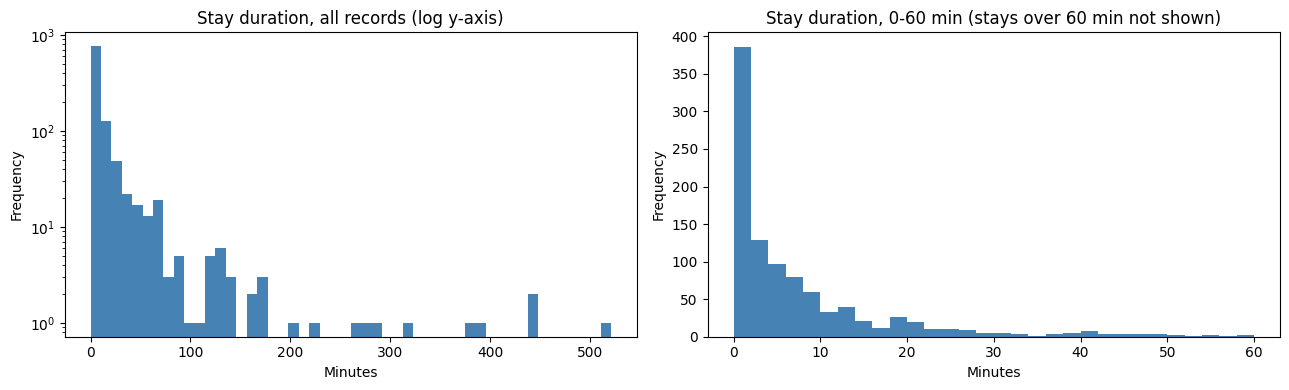

stays over 60 min: 66 of 1049


In [61]:
# private passenger vehicles in loading zones: how much is missing, and how long do they stay?
pp = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
].copy()

# missing values are stored as the text '<null>'; turn them into real NaN
pp = pp.replace('<null>', pd.NA)

# how many are missing?
print("total records:", len(pp))
missing = pd.DataFrame({
    "missing": pp[['park_start', 'park_end', 'total_duration']].isna().sum(),
    "percent": (pp[['park_start', 'park_end', 'total_duration']].isna().mean() * 100).round(1),
})
print(missing)

# total_duration is text like '0:18:17' (h:mm:ss); convert to minutes
pp['duration_min'] = pd.to_timedelta(pp['total_duration']).dt.total_seconds() / 60

print(pp['duration_min'].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

# distribution: full range (log scale on y so the long tail is visible) and zoomed to 0-60 min
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

pp['duration_min'].dropna().plot.hist(bins=50, ax=axes[0], color='steelblue')
axes[0].set_yscale('log')
axes[0].set_title('Stay duration, all records (log y-axis)')
axes[0].set_xlabel('Minutes')

pp['duration_min'].dropna().plot.hist(bins=range(0, 62, 2), ax=axes[1], color='steelblue')
axes[1].set_title('Stay duration, 0-60 min (stays over 60 min not shown)')
axes[1].set_xlabel('Minutes')

plt.tight_layout()
plt.show()

print("stays over 60 min:", (pp['duration_min'] > 60).sum(), "of", pp['duration_min'].notna().sum())

1153 private passenger vehicles in loading zones
1112 with a park_start time


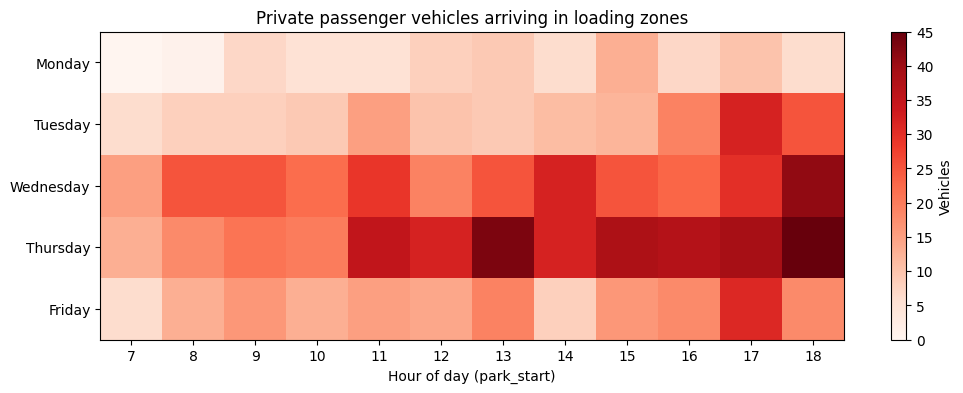

dow
Monday       1
Tuesday      5
Wednesday    6
Thursday     6
Friday       5
Name: Date, dtype: int64


In [62]:
# private passenger vehicles in loading zones: when do they arrive? (hour of day x day of week)
private_pass = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
].copy()
print(len(private_pass), "private passenger vehicles in loading zones")

# park_start is stored as the text '<null>' when missing; drop those rows
private_pass = private_pass[private_pass['park_start'] != '<null>']
print(len(private_pass), "with a park_start time")

private_pass['start'] = pd.to_datetime(private_pass['Date'] + ' ' + private_pass['park_start'])
private_pass['hour'] = private_pass['start'].dt.hour
private_pass['dow'] = private_pass['start'].dt.day_name()

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
tbl = pd.crosstab(private_pass['dow'], private_pass['hour']).reindex(order).dropna(how='all')

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(tbl, aspect='auto', cmap='Reds')
ax.set_xticks(range(len(tbl.columns)), tbl.columns)
ax.set_yticks(range(len(tbl.index)), tbl.index)
ax.set_xlabel('Hour of day (park_start)')
ax.set_title('Private passenger vehicles arriving in loading zones')
plt.colorbar(im, label='Vehicles')
plt.show()

# survey days per weekday: counts are higher on weekdays that were surveyed more often
print(private_pass.groupby('dow')['Date'].nunique().reindex(tbl.index))